In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bulkanalysis.plot import boxplot_pca

from melapa.OmicsDataset import OmicsDataset
from melapa.helper_plot import plot_boxplot_significance, boxplot_pca_significance
from melapa.LMM_helper import lmer_per_PC_2re

import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

In [2]:
table_of_pairs = pd.read_csv("/idiap/temp/group/genomics/AstroBF_fastq/RN22346/230106_A01366_0335_BHJJHNDSX5/3UTR_analysis_grouped/table_of_pairs.csv", index_col=0)

In [3]:
metadata_path = "/idiap/temp/group/genomics/AstroBF_fastq/RN22346/RN22346.xlsx"
metadata = pd.read_excel(metadata_path)
metadata['category'] = metadata["Sample Genotype"] + "_" + metadata["Sample Treatment"]


In [4]:
metadata

,project,name,limsid,date-received,Submission Type,Library Type,Sample Genotype,Sample Replicate Group,Sample Treatment,category
0,RN22346,1a,TAH5505A1,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,ctrl2,text,basal,ctrl2_basal
1,RN22346,5a,TAH5505A10,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,glib,text,basal,glib_basal
2,RN22346,5b,TAH5505A11,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,glib,text,A1 low,glib_A1 low
3,RN22346,5c,TAH5505A12,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,glib,text,A1 high,glib_A1 high
4,RN22346,6a,TAH5505A13,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,cbie,text,basal,cbie_basal
5,RN22346,6b,TAH5505A14,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,cbie,text,A1 low,cbie_A1 low
6,RN22346,6c,TAH5505A15,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,cbie,text,A1 high,cbie_A1 high
7,RN22346,3a,TAH5505A16,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,ctrl6,text,basal,ctrl6_basal
8,RN22346,3b,TAH5505A17,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,ctrl6,text,A1 low,ctrl6_A1 low
9,RN22346,3c,TAH5505A18,2022-12-12,RNA,NEBNext Ultra II Directional PolyA mRNA,ctrl6,text,A1 high,ctrl6_A1 high


In [5]:
df_PUDs = table_of_pairs[[col for col in table_of_pairs.columns if col.startswith('PUD_TAH')]]
df_PUDs.columns = [col.replace('PUD_', '') for col in df_PUDs.columns]


In [6]:
df_PUDs

,TAH5505A1,TAH5505A10,TAH5505A11,TAH5505A12,TAH5505A13,TAH5505A14,TAH5505A15,TAH5505A16,TAH5505A17,TAH5505A18,TAH5505A2,TAH5505A3,TAH5505A4,TAH5505A5,TAH5505A6,TAH5505A7,TAH5505A8,TAH5505A9
0,0.792080,0.841184,0.831043,0.809654,0.834446,0.850210,0.816880,0.825548,0.785174,0.791952,0.827335,0.827196,0.819231,0.804703,0.853190,0.882343,0.815038,0.864642
1,0.656822,0.625043,0.564440,0.625412,0.710210,0.670701,0.678403,0.668725,0.643232,0.628023,0.556411,0.541280,0.628664,0.665279,0.589307,0.626505,0.694737,0.537311
2,0.939693,0.958199,0.957446,0.943732,0.946920,0.940798,0.930883,0.951374,0.961668,0.961047,0.961149,0.952165,0.955778,1.000000,0.933991,0.910894,0.931833,0.960184
3,0.935225,0.856331,0.852260,0.873246,0.917337,0.869470,0.874548,0.908870,0.884398,0.904869,0.875475,0.863549,0.863122,0.895687,0.879741,0.885640,0.860280,0.830864
4,0.616084,0.485112,0.548771,0.524423,0.649282,0.513646,0.568958,0.572874,0.668694,0.610582,0.549410,0.510714,0.575303,0.607124,0.496791,0.639691,0.608676,0.559284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14798,0.630768,0.498988,0.561550,0.530114,0.543444,0.634436,0.683812,0.679079,0.630653,0.590214,0.630599,0.595927,0.672076,0.602620,0.794615,0.554486,0.565128,0.745650
14799,0.830002,0.795720,0.588746,0.527500,0.822496,0.851022,0.662583,0.874954,0.628364,0.867021,0.781956,0.792339,0.859172,0.700736,0.714987,0.889973,0.715925,0.766859
14800,0.879435,0.791650,0.875480,0.931798,0.682501,0.880222,0.879106,0.949605,0.953620,0.965798,0.906070,0.628830,0.879560,0.877140,0.910319,0.896908,0.890494,0.931427
14801,0.785713,0.755746,0.843314,0.777754,0.753113,0.887890,0.895148,0.863615,0.785286,0.956812,0.782661,0.604332,0.781147,0.769468,0.846029,0.772846,0.848142,0.747636


In [7]:
categories = {'ctrl_basal': ['TAH5505A1', 'TAH5505A16', 'TAH5505A4'],
 'ctrl_A1 low': ['TAH5505A17', 'TAH5505A2', 'TAH5505A5'],
 'ctrl_A1 high': ['TAH5505A18', 'TAH5505A3', 'TAH5505A6'],
 'vcp_basal': ['TAH5505A10', 'TAH5505A13', 'TAH5505A7'],
 'vcp_A1 low': ['TAH5505A11', 'TAH5505A14', 'TAH5505A8'],
 'vcp_A1 high': ['TAH5505A12', 'TAH5505A15', 'TAH5505A9']}

In [8]:
df_PUDs

,TAH5505A1,TAH5505A10,TAH5505A11,TAH5505A12,TAH5505A13,TAH5505A14,TAH5505A15,TAH5505A16,TAH5505A17,TAH5505A18,TAH5505A2,TAH5505A3,TAH5505A4,TAH5505A5,TAH5505A6,TAH5505A7,TAH5505A8,TAH5505A9
0,0.792080,0.841184,0.831043,0.809654,0.834446,0.850210,0.816880,0.825548,0.785174,0.791952,0.827335,0.827196,0.819231,0.804703,0.853190,0.882343,0.815038,0.864642
1,0.656822,0.625043,0.564440,0.625412,0.710210,0.670701,0.678403,0.668725,0.643232,0.628023,0.556411,0.541280,0.628664,0.665279,0.589307,0.626505,0.694737,0.537311
2,0.939693,0.958199,0.957446,0.943732,0.946920,0.940798,0.930883,0.951374,0.961668,0.961047,0.961149,0.952165,0.955778,1.000000,0.933991,0.910894,0.931833,0.960184
3,0.935225,0.856331,0.852260,0.873246,0.917337,0.869470,0.874548,0.908870,0.884398,0.904869,0.875475,0.863549,0.863122,0.895687,0.879741,0.885640,0.860280,0.830864
4,0.616084,0.485112,0.548771,0.524423,0.649282,0.513646,0.568958,0.572874,0.668694,0.610582,0.549410,0.510714,0.575303,0.607124,0.496791,0.639691,0.608676,0.559284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14798,0.630768,0.498988,0.561550,0.530114,0.543444,0.634436,0.683812,0.679079,0.630653,0.590214,0.630599,0.595927,0.672076,0.602620,0.794615,0.554486,0.565128,0.745650
14799,0.830002,0.795720,0.588746,0.527500,0.822496,0.851022,0.662583,0.874954,0.628364,0.867021,0.781956,0.792339,0.859172,0.700736,0.714987,0.889973,0.715925,0.766859
14800,0.879435,0.791650,0.875480,0.931798,0.682501,0.880222,0.879106,0.949605,0.953620,0.965798,0.906070,0.628830,0.879560,0.877140,0.910319,0.896908,0.890494,0.931427
14801,0.785713,0.755746,0.843314,0.777754,0.753113,0.887890,0.895148,0.863615,0.785286,0.956812,0.782661,0.604332,0.781147,0.769468,0.846029,0.772846,0.848142,0.747636


In [9]:
PUD_dataset = OmicsDataset(df=df_PUDs, 
                           df_log=df_PUDs,
                           treatments=categories, treatment_name='category', 
                           feature_type='PUD', nb_comp=18)

In [10]:
PUD_dataset.df

,TAH5505A1,TAH5505A16,TAH5505A4,TAH5505A17,TAH5505A2,TAH5505A5,TAH5505A18,TAH5505A3,TAH5505A6,TAH5505A10,TAH5505A13,TAH5505A7,TAH5505A11,TAH5505A14,TAH5505A8,TAH5505A12,TAH5505A15,TAH5505A9
0,0.792080,0.825548,0.819231,0.785174,0.827335,0.804703,0.791952,0.827196,0.853190,0.841184,0.834446,0.882343,0.831043,0.850210,0.815038,0.809654,0.816880,0.864642
1,0.656822,0.668725,0.628664,0.643232,0.556411,0.665279,0.628023,0.541280,0.589307,0.625043,0.710210,0.626505,0.564440,0.670701,0.694737,0.625412,0.678403,0.537311
2,0.939693,0.951374,0.955778,0.961668,0.961149,1.000000,0.961047,0.952165,0.933991,0.958199,0.946920,0.910894,0.957446,0.940798,0.931833,0.943732,0.930883,0.960184
3,0.935225,0.908870,0.863122,0.884398,0.875475,0.895687,0.904869,0.863549,0.879741,0.856331,0.917337,0.885640,0.852260,0.869470,0.860280,0.873246,0.874548,0.830864
4,0.616084,0.572874,0.575303,0.668694,0.549410,0.607124,0.610582,0.510714,0.496791,0.485112,0.649282,0.639691,0.548771,0.513646,0.608676,0.524423,0.568958,0.559284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14798,0.630768,0.679079,0.672076,0.630653,0.630599,0.602620,0.590214,0.595927,0.794615,0.498988,0.543444,0.554486,0.561550,0.634436,0.565128,0.530114,0.683812,0.745650
14799,0.830002,0.874954,0.859172,0.628364,0.781956,0.700736,0.867021,0.792339,0.714987,0.795720,0.822496,0.889973,0.588746,0.851022,0.715925,0.527500,0.662583,0.766859
14800,0.879435,0.949605,0.879560,0.953620,0.906070,0.877140,0.965798,0.628830,0.910319,0.791650,0.682501,0.896908,0.875480,0.880222,0.890494,0.931798,0.879106,0.931427
14801,0.785713,0.863615,0.781147,0.785286,0.782661,0.769468,0.956812,0.604332,0.846029,0.755746,0.753113,0.772846,0.843314,0.887890,0.848142,0.777754,0.895148,0.747636


In [11]:
palette_category = {"ctrl_basal": 'palegreen', "ctrl_A1 low": "limegreen", "ctrl_A1 high": "forestgreen", "vcp_basal": "pink", "vcp_A1 low": "hotpink", "vcp_A1 high": "deeppink" }

palette = sns.color_palette([palette_category[cat] for cat in categories.keys()])

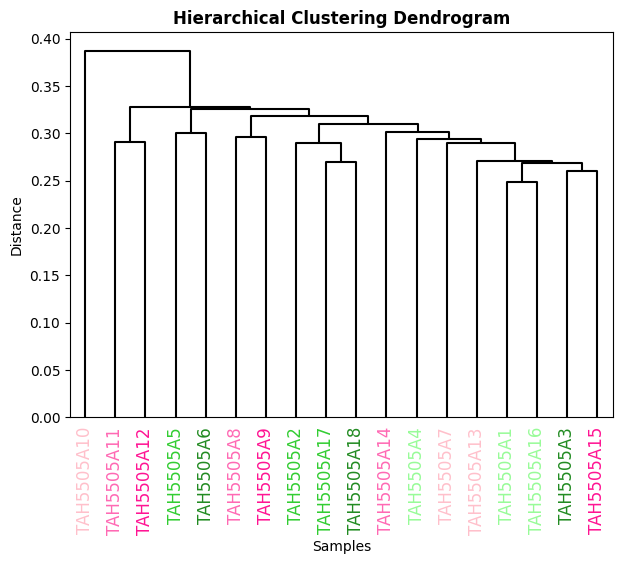

In [12]:
PUD_dataset.hierarchical_clustering(palette=palette, treatments=categories, color_threshold=0)

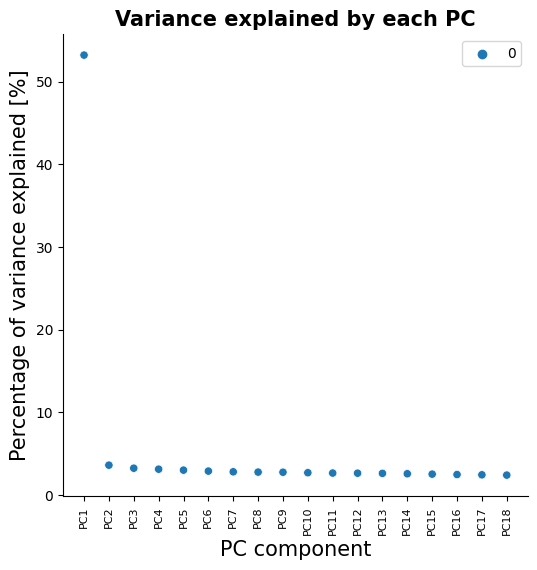

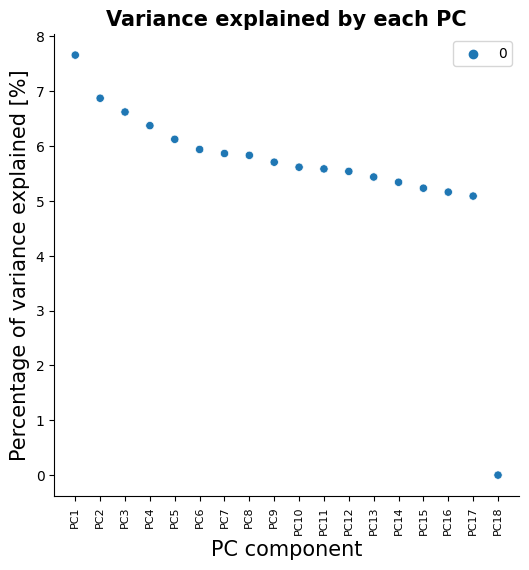

In [13]:
PUD_dataset.perform_svd_analysis(top_n=18)
plt.xticks(rotation=90, fontsize=8);

In [14]:
metadata.columns

Index(['project', 'name', 'limsid', 'date-received', 'Submission Type',
       'Library Type', 'Sample Genotype', 'Sample Replicate Group',
       'Sample Treatment', 'category'],
      dtype='object')

In [15]:
PUD_dataset.pca = PUD_dataset.pca.merge(metadata[['category', 'Sample Treatment', 'Sample Genotype', 'limsid']], left_index=True, right_on='limsid')

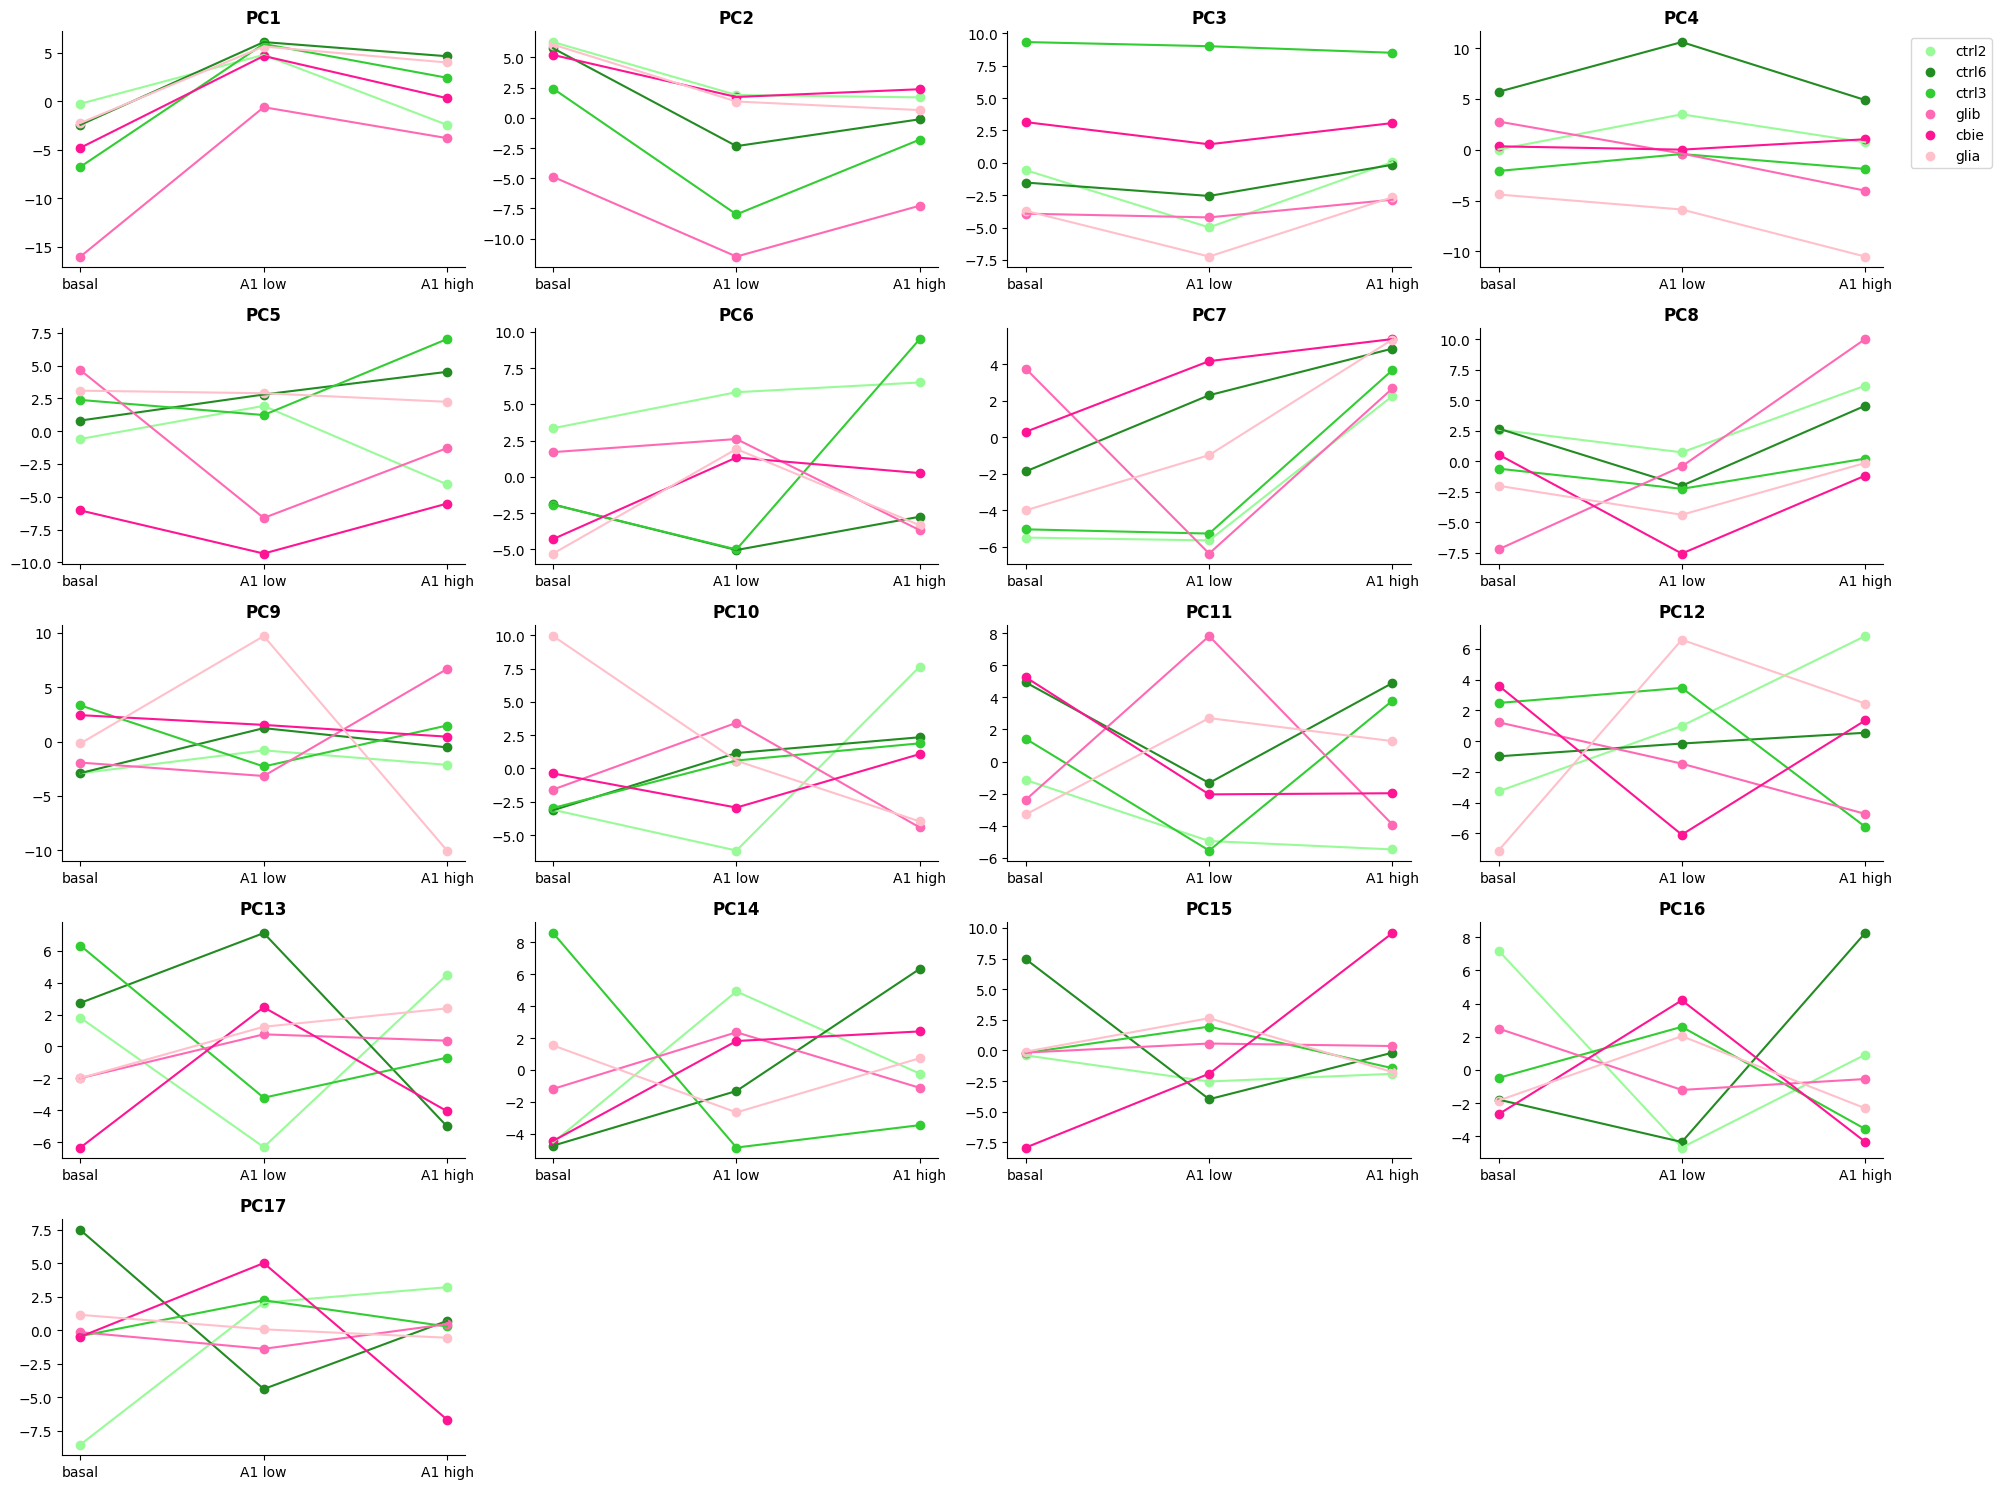

In [16]:
palette_genotype = {"ctrl2": 'palegreen', "ctrl3": "limegreen", "ctrl6": "forestgreen", "glia": "pink", "glib": "hotpink", "cbie": "deeppink" }
plt.figure(figsize=(20, 15))
for pc in range(17):
    plt.subplot(5, 4, pc+1)
    for genotype in PUD_dataset.pca['Sample Genotype'].unique():
        subset = PUD_dataset.pca[PUD_dataset.pca['Sample Genotype'] == genotype]
        # subset.index = [idx.split('_')[1] for idx in subset.index]
        subset.set_index("Sample Treatment", inplace=True)
        subset = subset.loc[["basal", "A1 low", "A1 high"]]
        plt.scatter(x=subset.index, y=subset[f'PC{pc+1}'], label=genotype, color=palette_genotype[genotype])
        plt.plot(subset.index, subset[f'PC{pc+1}'], color=palette_genotype[genotype])
    if pc == 3:
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    sns.despine()
    plt.title(f"PC{pc+1}", weight='bold')
plt.tight_layout()

In [18]:
PUD_dataset.pca['mutation'] = ["ctrl" if "ctrl" in genotype else "vcp" for genotype in PUD_dataset.pca['Sample Genotype']]

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=3.20e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=5.93e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=1.07e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=3.09e-02
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=1.02e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=3.72e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=2.78e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=1.96e-01


... (11 outputs left out)

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=7.58e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=3.04e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


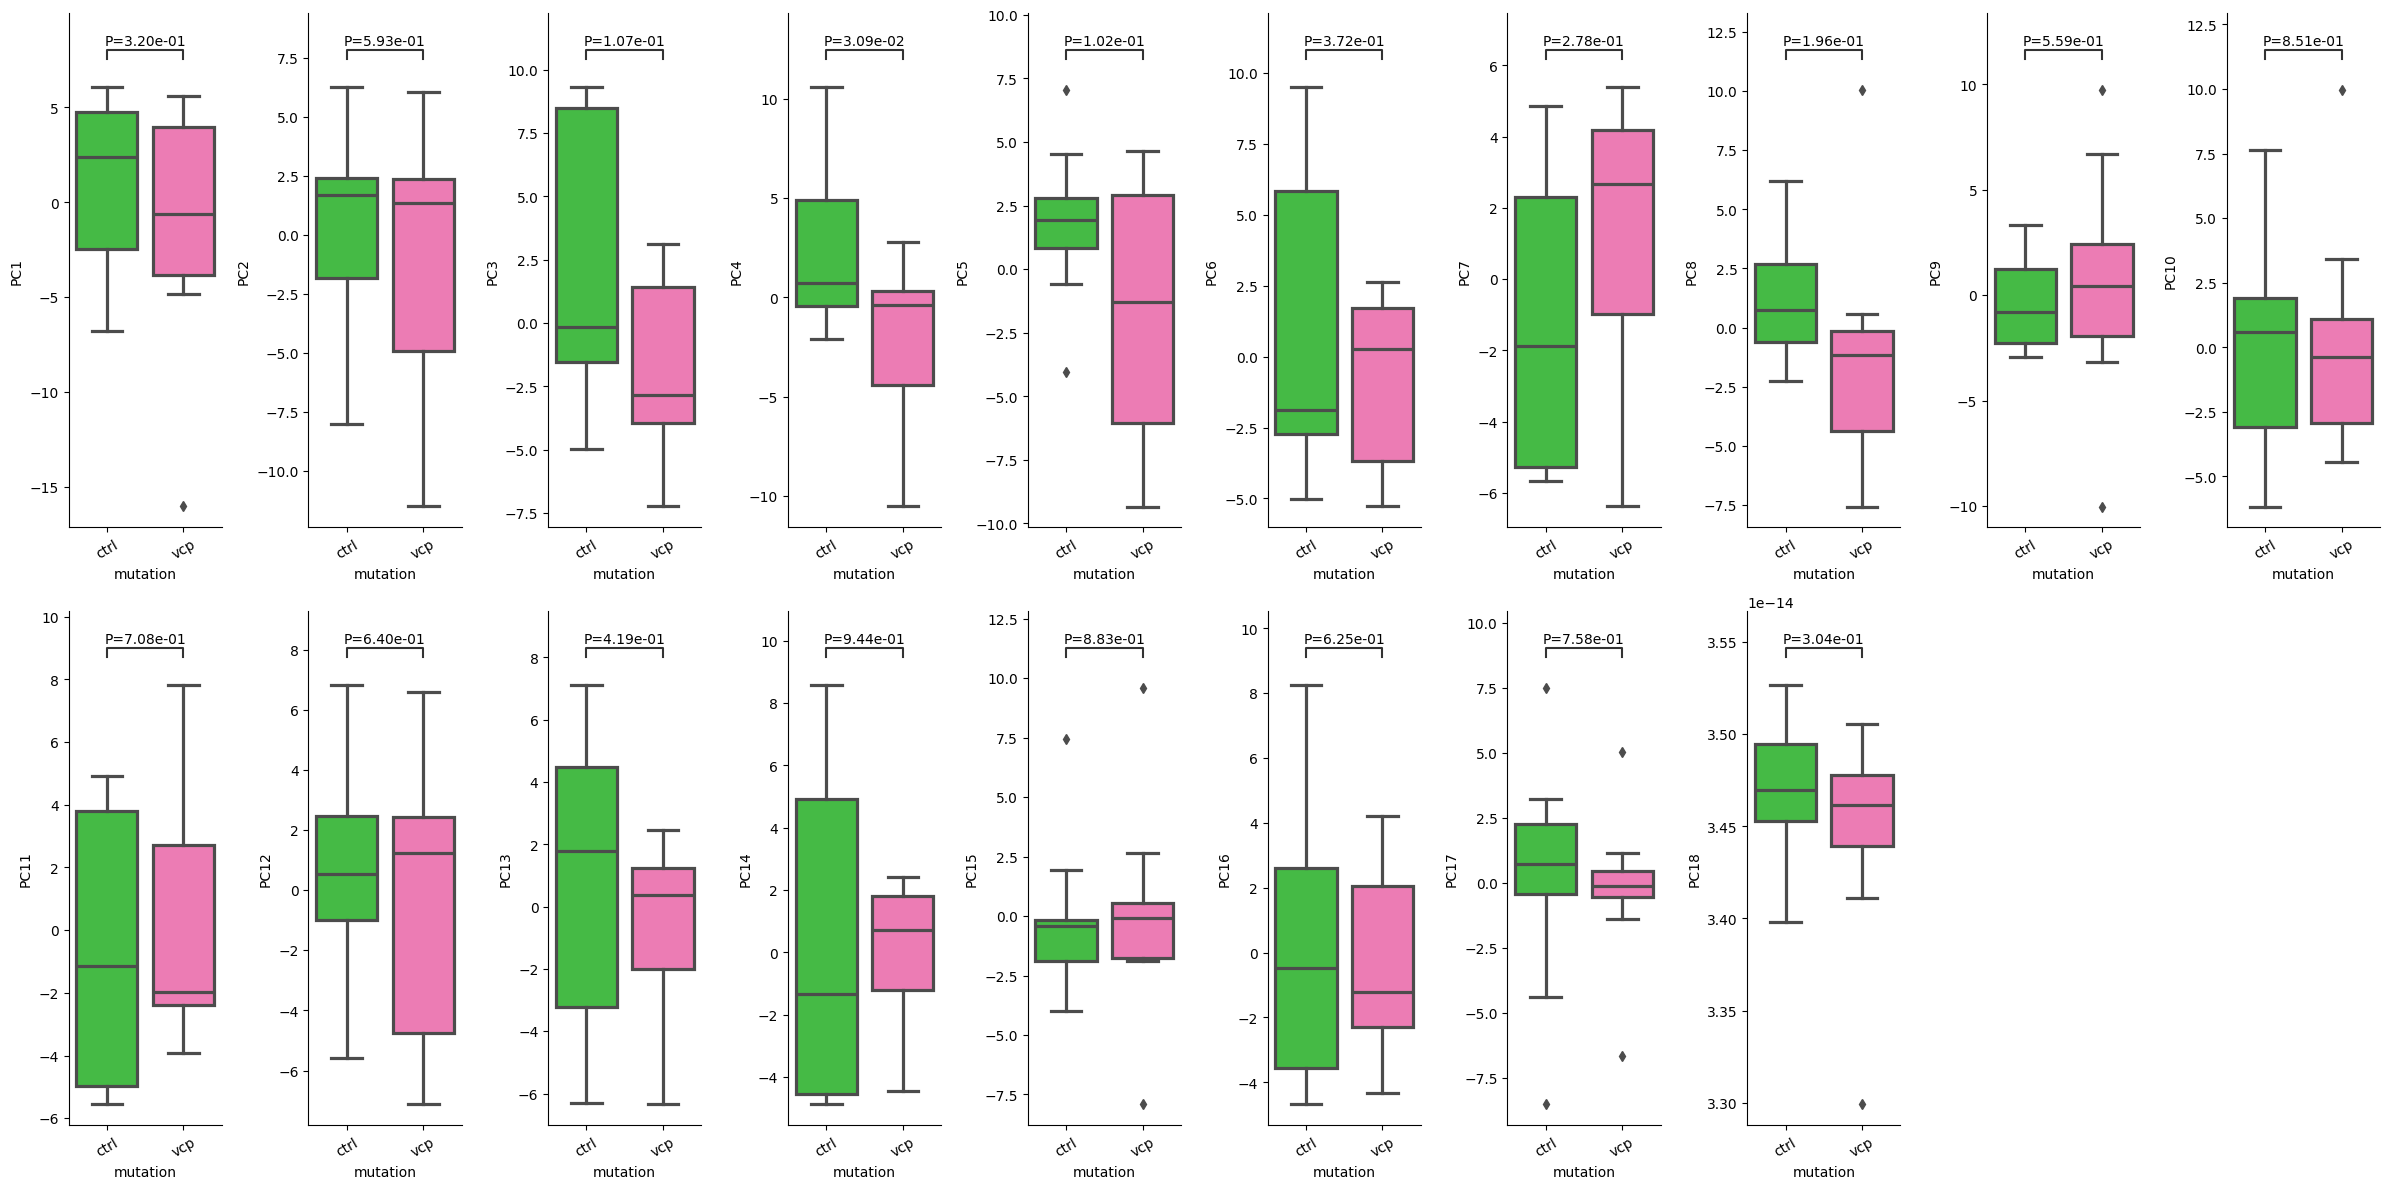

In [19]:
boxplot_pca_significance(PUD_dataset.pca, treatment_col='mutation', fontsize=10, palette={'ctrl': 'limegreen', 'vcp': 'hotpink'})

In [23]:
PUD_dataset.pca['treatment'] = PUD_dataset.pca['Sample Treatment']

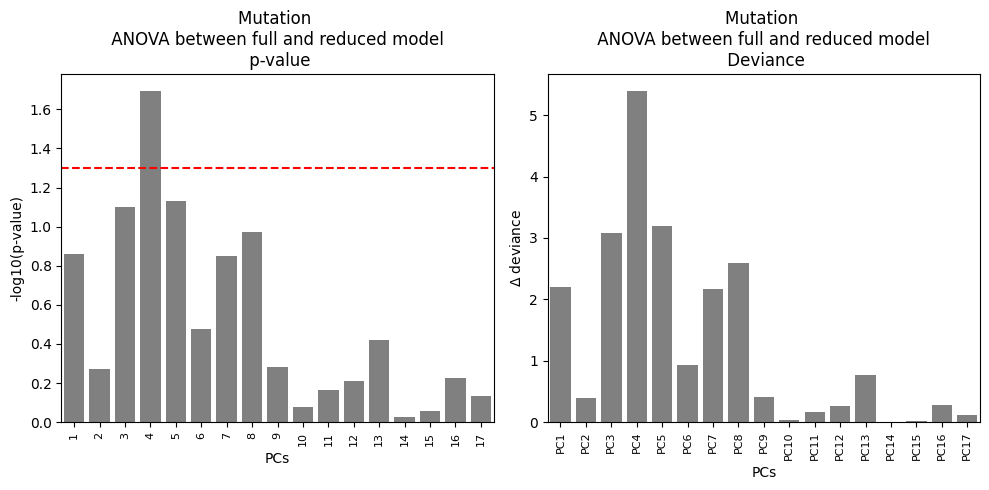

In [24]:
%%capture cap --no-display

from melapa.LMM_helper import lmer_per_PC_re

## See which component captures the difference sensitive/resistant

plt.figure(figsize=(10, 5))
## See which component captures the batch
anovas = []
p_vals = []

for i in range(17):
    PC = i+1
    anova, p_val = lmer_per_PC_re(PUD_dataset.pca, random_effects=['treatment'], fixed_effect='mutation', PC=PC)
    anovas.append(anova)
    p_vals.append(p_val)

plt.subplot(1, 2, 1)
sns.barplot(x=np.arange(1, 18), y=-np.log10(p_vals), color='grey')
plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel('-log10(p-value)')
plt.title(f'Mutation \n ANOVA between full and reduced model \n p-value')

delta_deviances = []
for PC in range(len(anovas)):
    delta_deviance = anovas[PC].loc['MODEL2', 'deviance'] - anovas[PC].loc['MODEL1', 'deviance'] ## Difference between the full and reduced model
    delta_deviances.append(delta_deviance)

plt.subplot(1, 2, 2)
sns.barplot(x=[f"PC{i+1}" for i in range(len(anovas))], y=delta_deviances, color='grey')
#plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel(r'$\Delta$ deviance')
plt.title(f'Mutation \n ANOVA between full and reduced model \n Deviance')

plt.tight_layout()

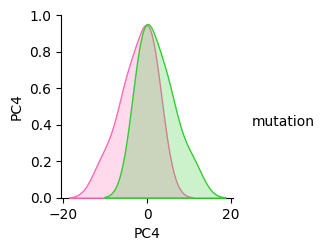

In [26]:
PCs = [f"PC{PC+1}" for PC in list(np.argwhere(np.array(p_vals) < 0.05).flatten())] + ['mutation']
sns.pairplot(PUD_dataset.pca[PCs], hue='mutation',  palette={'ctrl': 'limegreen', 'vcp': 'hotpink'})

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=6.15e-03
A1 low vs. A1 high: P=7.14e-02
basal vs. A1 high: P=4.81e-02
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=5.91e-02


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


A1 low vs. A1 high: P=4.72e-01
basal vs. A1 high: P=9.47e-02
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=5.65e-01
A1 low vs. A1 high: P=4.34e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


basal vs. A1 high: P=8.46e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=7.59e-01
A1 low vs. A1 high: P=3.79e-01


... (25 outputs left out)

p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=7.66e-01
A1 low vs. A1 high: P=6.00e-01
basal vs. A1 high: P=9.17e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=1.30e-01
A1 low vs. A1 high: P=9.71e-02
basal vs. A1 high: P=4.62e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


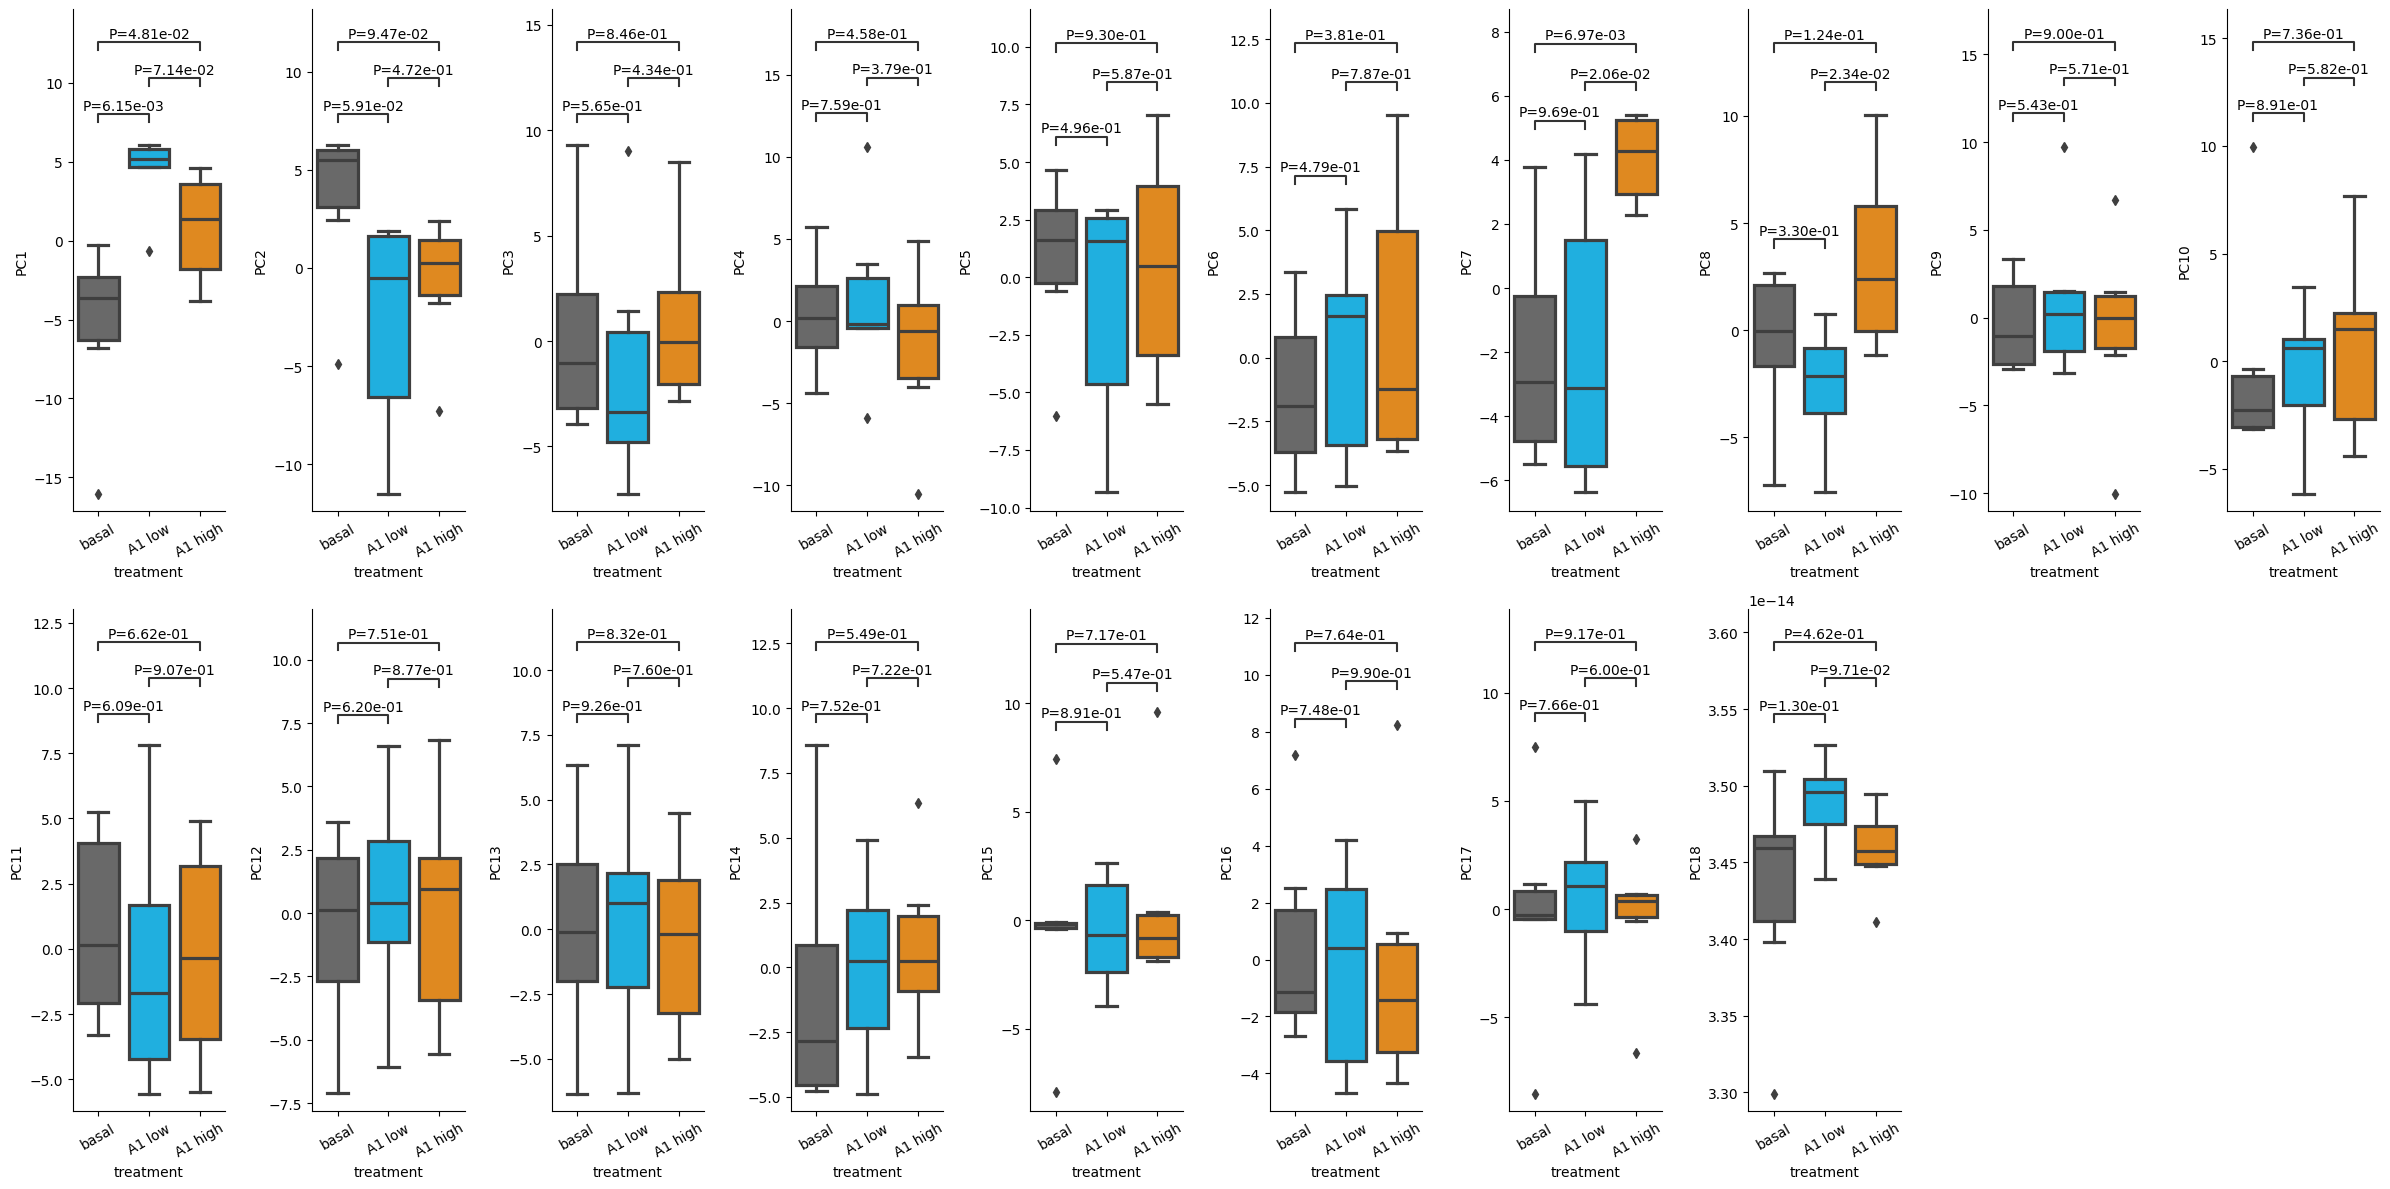

In [27]:
boxplot_pca_significance(PUD_dataset.pca, treatment_col='treatment', fontsize=10, palette={'basal': 'dimgray', 'A1 low': 'deepskyblue', "A1 high": "darkorange"})

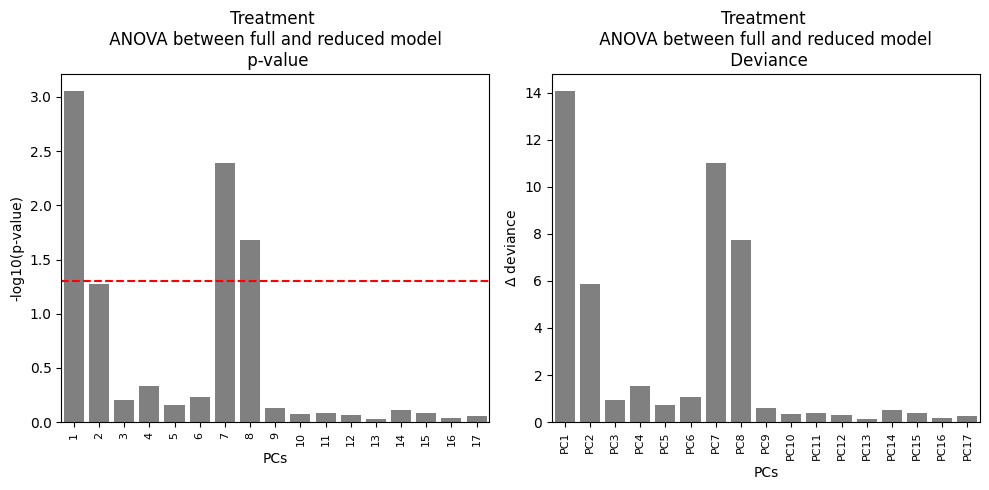

In [ ]:
%%capture cap --no-display

from melapa.LMM_helper import lmer_per_PC_re

## See which component captures the difference sensitive/resistant

plt.figure(figsize=(10, 5))
## See which component captures the batch
anovas = []
p_vals = []

for i in range(17):
    PC = i+1
    anova, p_val = lmer_per_PC_re(PUD_dataset.pca, 
                                  random_effects=['mutation'], 
                                  fixed_effect='treatment', PC=PC)
    anovas.append(anova)
    p_vals.append(p_val)

plt.subplot(1, 2, 1)
sns.barplot(x=np.arange(1, 18), y=-np.log10(p_vals), color='grey')
plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel('-log10(p-value)')
plt.title(f'Treatment \n ANOVA between full and reduced model \n p-value')

delta_deviances = []
for PC in range(len(anovas)):
    delta_deviance = anovas[PC].loc['MODEL2', 'deviance'] - anovas[PC].loc['MODEL1', 'deviance'] ## Difference between the full and reduced model
    delta_deviances.append(delta_deviance)

plt.subplot(1, 2, 2)
sns.barplot(x=[f"PC{i+1}" for i in range(len(anovas))], y=delta_deviances, color='grey')
#plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel(r'$\Delta$ deviance')
plt.title(f'Treatment \n ANOVA between full and reduced model \n Deviance')

plt.tight_layout()

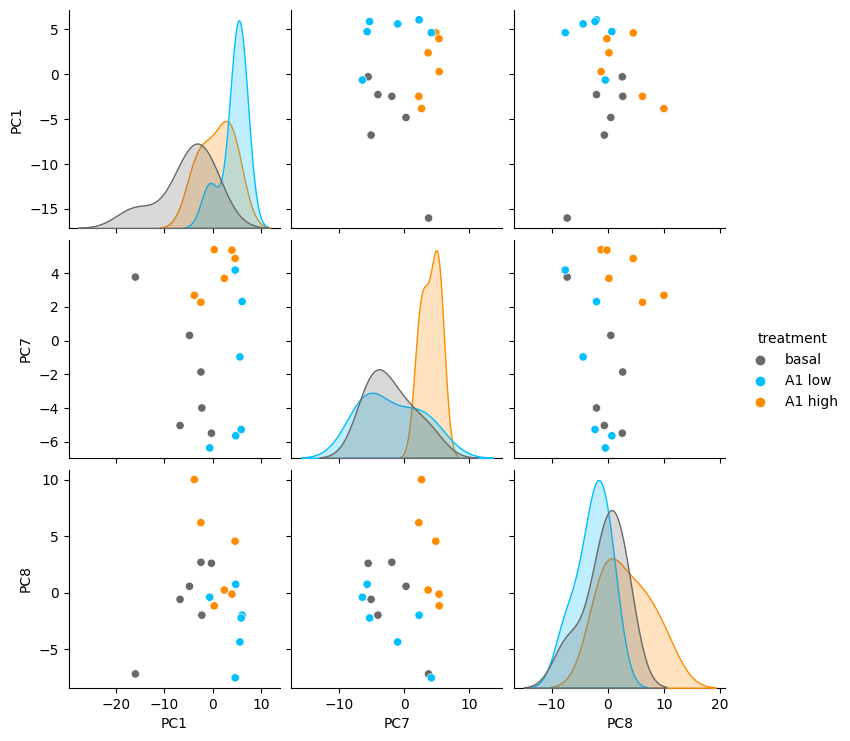

In [30]:
PCs = [f"PC{PC+1}" for PC in list(np.argwhere(np.array(p_vals) < 0.05).flatten())] + ['treatment']
sns.pairplot(PUD_dataset.pca[PCs], hue='treatment',  palette={'basal': 'dimgray', 'A1 low': 'deepskyblue', "A1 high": "darkorange"})